# XGBoost — Training and Analysis

Trains XGBoost on the **leakage-corrected** CICEVSE2024 network-traffic dataset. Gradient-boosted trees, grown level-wise with the histogram method.

| | |
|---|---|
| **Dataset** | CICEVSE2024 network traffic — 15 classes (14 attacks + benign) |
| **Features** | 60, after dropping six capture timestamps and `src_port` |
| **Rows** | 1,198,151 after deduplication |
| **Task** | Multiclass. Binary was dropped: only 81 benign flows exist |
| **Headline metric** | Macro-F1 |

> **Settings are fixed in advance**, the same as in `src/evaluation/run_boosting.py`.
> The validation split is used only for early stopping; the test split is scored once.
> Class imbalance is handled with balanced sample weights, the same rule as
> `class_weight='balanced'` for the other models.
>
> Multi-seed result: see `evaluation_results/boosting/BOOSTING_RESULTS.md`.


In [1]:
import os
import sys

# Make the repository importable (the wrapper lives in src/models/boosting.py).
ROOT = os.path.abspath('../../..') if os.path.exists('../../../src') else os.path.abspath('.')
sys.path.insert(0, ROOT)

import joblib

import numpy as np

import pandas as pd

import matplotlib.pyplot as plt

import seaborn as sns

from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report



# Plotting config

%matplotlib inline

plt.rcParams['figure.dpi'] = 100

sns.set_theme(style='whitegrid', palette='deep')
from src.models.boosting import LabelEncodedBooster


## 1. Load Data

Load the preprocessed train, validation, and test datasets. Note: ensure `preprocess.py` has been run previously.

In [2]:
# Adjust path assuming the notebook runs from the project root or src/models/random_forest

import sys

if os.path.exists('../../../data/processed'):

    DATA_DIR = '../../../data/processed'

elif os.path.exists('data/processed'):

    DATA_DIR = 'data/processed'

else:

    DATA_DIR = '../data/processed' # fallback



print(f"Using data directory: {DATA_DIR}")



X_train = pd.read_csv(os.path.join(DATA_DIR, "X_train.csv"))

y_train = pd.read_csv(os.path.join(DATA_DIR, "y_train.csv"))

X_val = pd.read_csv(os.path.join(DATA_DIR, "X_val.csv"))

y_val = pd.read_csv(os.path.join(DATA_DIR, "y_val.csv"))

X_test = pd.read_csv(os.path.join(DATA_DIR, "X_test.csv"))

y_test = pd.read_csv(os.path.join(DATA_DIR, "y_test.csv"))



y_train_multi = y_train["Label_Multiclass"].values.ravel()

y_val_multi = y_val["Label_Multiclass"].values.ravel()

y_test_multi = y_test["Label_Multiclass"].values.ravel()



print("Data loaded successfully!")

print(f"X_train shape: {X_train.shape}")

Using data directory: ../../../data/processed


Data loaded successfully!
X_train shape: (838705, 60)


In [3]:
# ── Leakage guard (issues #46, #58) ──────────────────────────────────────────
# The published CICEVSE2024 pipeline keeps six absolute capture timestamps that
# identify the *recording* rather than the traffic: a decision tree on
# `bidirectional_first_seen_ms` alone scores 1.0000 on the 15-class target.
# `src_port` is a weaker version of the same thing — ephemeral ports are
# allocated near-sequentially, so they band per capture (0.4028 alone).
#
# Both are dropped by `preprocess.py`. This cell fails loudly if you are sitting
# on data built by an older version of the pipeline, because every number below
# would be meaningless.
LEAKING = [
    "bidirectional_first_seen_ms", "bidirectional_last_seen_ms",
    "src2dst_first_seen_ms", "src2dst_last_seen_ms",
    "dst2src_first_seen_ms", "dst2src_last_seen_ms",
    "src_port",
]

# Notebooks load either the full matrix or a sample frame for visualisation.
_frame = next((globals()[n] for n in ("X_train", "X_train_sample") if n in globals()), None)
assert _frame is not None, "Run the data-loading cell above first."

present = [c for c in LEAKING if c in _frame.columns]
assert not present, (
    f"Leaking columns found: {present}. Regenerate with: make data-process"
)
print(f"Leakage guard passed — {_frame.shape[1]} features, none of them capture fingerprints.")

# Relative timing is behavioural and is deliberately retained.
kept = [c for c in _frame.columns if c.endswith("_duration_ms") or c.endswith("_piat_ms")]
print(f"Relative timing features retained: {len(kept)}")


Leakage guard passed — 60 features, none of them capture fingerprints.
Relative timing features retained: 15


## 1.1 Dataset Overview

Quick inspection of the training data: shape, data types, summary statistics, and missing value check.

In [4]:
print(f"X_train shape : {X_train.shape}")

print(f"X_val shape   : {X_val.shape}")

print(f"X_test shape  : {X_test.shape}")

print(f"\nNumber of features: {X_train.shape[1]}")

print(f"\nData types:\n{X_train.dtypes.value_counts()}")

print(f"\nMissing values per column (if any):")

missing = X_train.isnull().sum()

missing_cols = missing[missing > 0]

if len(missing_cols) == 0:

    print("  None — all features are clean.")

else:

    print(missing_cols)



print("\nSummary Statistics (first 10 features):")

X_train.iloc[:, :10].describe().round(3)

X_train shape : (838705, 60)
X_val shape   : (179723, 60)
X_test shape  : (179723, 60)

Number of features: 60

Data types:
float64    60
Name: count, dtype: int64

Missing values per column (if any):
  None — all features are clean.

Summary Statistics (first 10 features):


,dst_port,protocol,ip_version,bidirectional_duration_ms,bidirectional_packets,bidirectional_bytes,src2dst_duration_ms,src2dst_packets,src2dst_bytes,dst2src_duration_ms
count,838705.000,838705.000,838705.000,838705.000,838705.000,838705.000,838705.000,838705.000,838705.000,838705.000
mean,0.000,-0.000,0.000,0.000,0.000,0.000,-0.000,0.000,0.000,-0.000
std,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000
min,-0.269,-2.700,-0.007,-2.051,-0.011,-0.003,-2.051,-0.011,-0.003,-0.451
25%,-0.266,-0.154,-0.007,0.453,-0.004,-0.002,0.453,-0.004,-0.002,-0.451
50%,-0.260,-0.154,-0.007,0.487,-0.002,-0.002,0.487,-0.002,-0.002,-0.451
75%,-0.260,-0.154,-0.007,0.495,-0.002,-0.002,0.495,-0.002,-0.002,-0.451
max,7.327,116.443,152.631,13.340,608.150,593.643,13.339,600.804,593.899,21.340


## 1.2 Train / Validation / Test Split Sizes

Visualise the data split proportions to verify the 70/15/15 split from preprocessing.

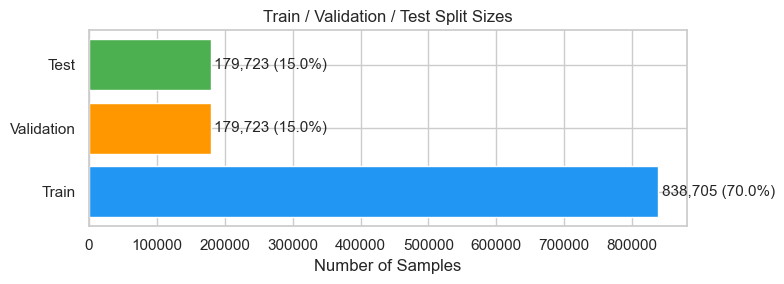

     Split  Samples  Percentage
     Train   838705        70.0
Validation   179723        15.0
      Test   179723        15.0


In [5]:
split_sizes = pd.DataFrame({

    'Split': ['Train', 'Validation', 'Test'],

    'Samples': [len(X_train), len(X_val), len(X_test)]

})

split_sizes['Percentage'] = (split_sizes['Samples'] / split_sizes['Samples'].sum() * 100).round(1)



fig, ax = plt.subplots(figsize=(8, 3))

bars = ax.barh(split_sizes['Split'], split_sizes['Samples'], color=['#2196F3', '#FF9800', '#4CAF50'])

for bar, pct in zip(bars, split_sizes['Percentage']):

    ax.text(bar.get_width() + 5000, bar.get_y() + bar.get_height()/2,

            f'{bar.get_width():,.0f} ({pct}%)', va='center', fontsize=11)

ax.set_xlabel('Number of Samples')

ax.set_title('Train / Validation / Test Split Sizes')

plt.tight_layout()

plt.show()



print(split_sizes.to_string(index=False))

## 1.3 Visualize Class Distributions

Before training the model, let's visualize the class distributions of our training dataset for Multiclass targets.

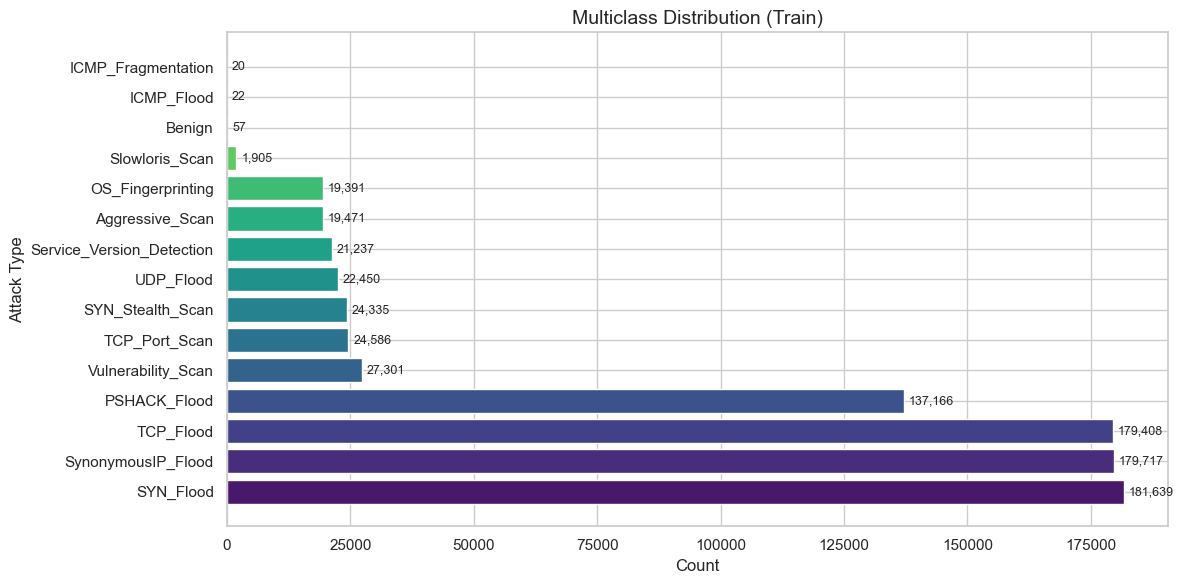


Multiclass label counts:
Label_Multiclass
SYN_Flood                    181639
SynonymousIP_Flood           179717
TCP_Flood                    179408
PSHACK_Flood                 137166
Vulnerability_Scan            27301
TCP_Port_Scan                 24586
SYN_Stealth_Scan              24335
UDP_Flood                     22450
Service_Version_Detection     21237
Aggressive_Scan               19471
OS_Fingerprinting             19391
Slowloris_Scan                 1905
Benign                           57
ICMP_Flood                       22
ICMP_Fragmentation               20


In [6]:
multi_counts = y_train['Label_Multiclass'].value_counts()

colors = sns.color_palette('viridis', len(multi_counts))



fig, ax = plt.subplots(figsize=(12, 6))

ax.barh(multi_counts.index, multi_counts.values, color=colors)

ax.set_title('Multiclass Distribution (Train)', fontsize=14)

ax.set_xlabel('Count')

ax.set_ylabel('Attack Type')

for i, val in enumerate(multi_counts.values):

    ax.text(val + 1000, i, f'{val:,}', va='center', fontsize=9)



plt.tight_layout()

plt.show()



print("\nMulticlass label counts:")

print(multi_counts.to_string())

## 1.4 Feature Correlation Heatmap

Visualise the pairwise Pearson correlations of the top 30 features (by variance) to identify multicollinearity.

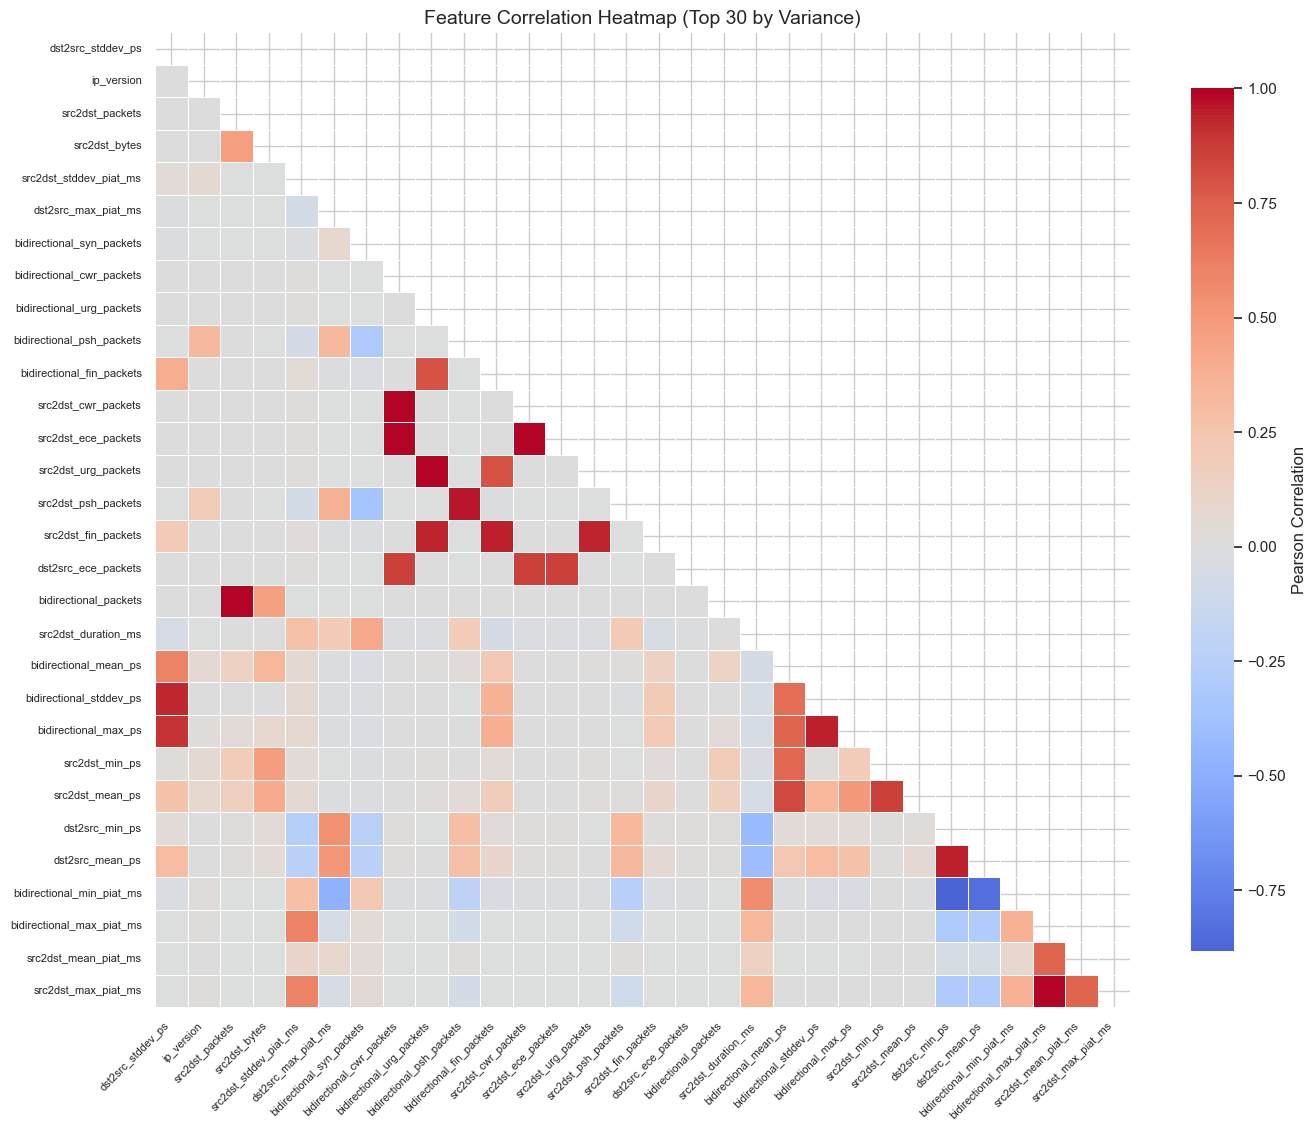

In [7]:
# Select top 30 features by variance for readability

top_features = X_train.var().nlargest(30).index.tolist()

corr_matrix = X_train[top_features].corr()



plt.figure(figsize=(14, 12))

mask = np.triu(np.ones_like(corr_matrix, dtype=bool))

sns.heatmap(corr_matrix, mask=mask, cmap='coolwarm', center=0,

            square=True, linewidths=0.5, fmt='.1f',

            cbar_kws={'shrink': 0.8, 'label': 'Pearson Correlation'})

plt.title('Feature Correlation Heatmap (Top 30 by Variance)', fontsize=14)

plt.xticks(rotation=45, ha='right', fontsize=8)

plt.yticks(fontsize=8)

plt.tight_layout()

plt.show()

## 1.5 Feature Distribution Box Plots

Box plots of the top 10 highest-variance features to visualise their range and spread after StandardScaler normalisation.

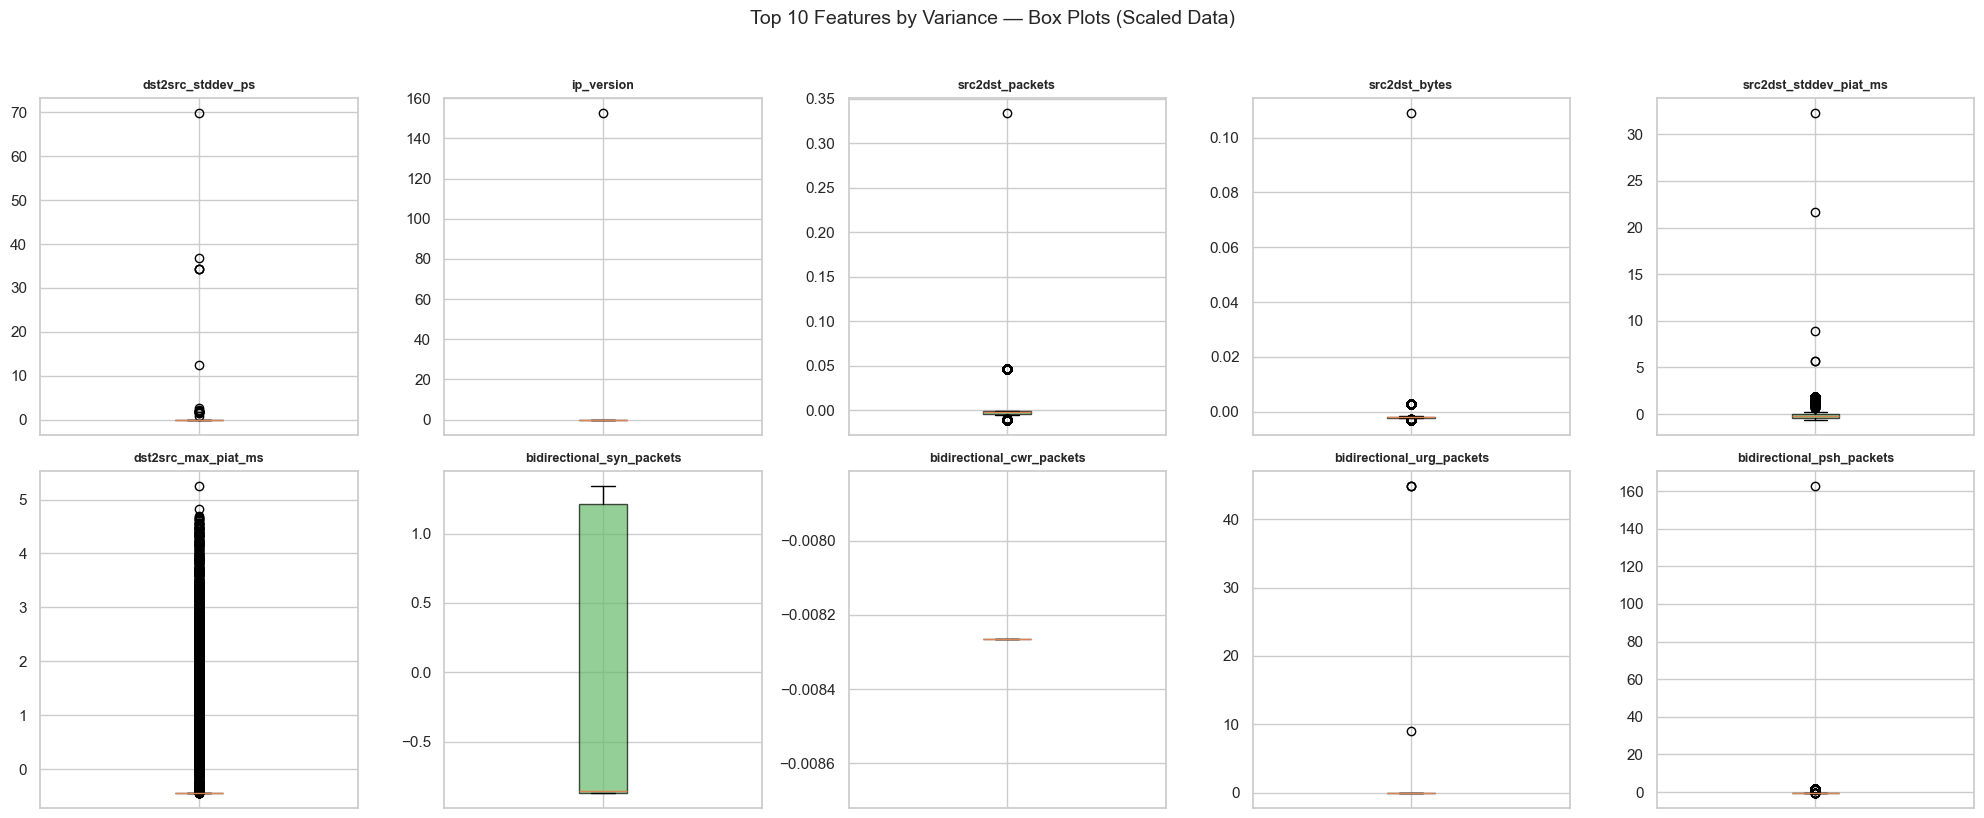

In [8]:
top10 = X_train.var().nlargest(10).index.tolist()



fig, axes = plt.subplots(2, 5, figsize=(20, 8))

axes = axes.flatten()



for i, col in enumerate(top10):

    sample = X_train[col].sample(n=min(10000, len(X_train)), random_state=42)

    axes[i].boxplot(sample.values, vert=True, patch_artist=True,

                    boxprops=dict(facecolor='#66BB6A', alpha=0.7))

    axes[i].set_title(col, fontsize=9, fontweight='bold')

    axes[i].tick_params(axis='x', labelbottom=False)



plt.suptitle('Top 10 Features by Variance — Box Plots (Scaled Data)', fontsize=14, y=1.02)

plt.tight_layout()

plt.show()

## 2. Train XGBoost

Fixed settings, early stopping on the validation split after 30 rounds without improvement.

In [9]:
import time

model = LabelEncodedBooster(
    "xgboost", 42,
    n_estimators=400, max_depth=8, learning_rate=0.1,
    subsample=0.8, colsample_bytree=0.8,
)
t0 = time.perf_counter()
model.fit(X_train, y_train_multi, X_val, y_val_multi)
print(f"Trained in {time.perf_counter() - t0:.1f} s")
inner = model.model
print("Best round:", getattr(inner, "best_iteration", None) or getattr(inner, "best_iteration_", None))

best_multi_model = model

Trained in 31.2 s
Best round: 112


## 3. Evaluation Setup

In [10]:
def evaluate_model(model, X, y, title_prefix=""):
    """
    Report macro-F1 first.

    Accuracy on this dataset is dominated by the volumetric floods, which every
    model solves, so it compresses genuinely different models into the same
    number. Macro-F1 weights each class equally and is what the write-up quotes.
    """
    preds = model.predict(X)

    acc = accuracy_score(y, preds)
    f1_macro = f1_score(y, preds, average="macro", zero_division=0)
    f1_weighted = f1_score(y, preds, average="weighted", zero_division=0)

    print(f"--- {title_prefix} ---")
    print(f"Macro F1-Score : {f1_macro:.4f}   <- headline")
    print(f"Weighted F1    : {f1_weighted:.4f}")
    print(f"Accuracy       : {acc:.4f}   (inflated by the flood classes)")
    print("\nClassification report:")
    print(classification_report(y, preds, zero_division=0))

    labels = sorted(np.unique(np.concatenate([np.asarray(y), np.asarray(preds)])))
    cm = confusion_matrix(y, preds, labels=labels)
    size = max(8, len(labels) * 0.75)
    plt.figure(figsize=(size + 2, size))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
                xticklabels=labels, yticklabels=labels, cbar_kws={"shrink": 0.7})
    plt.title(f"{title_prefix} — confusion matrix")
    plt.ylabel("Actual"); plt.xlabel("Predicted")
    plt.xticks(rotation=45, ha="right", fontsize=8); plt.yticks(fontsize=8)
    plt.tight_layout(); plt.show()
    return preds


## 4. Evaluate Multiclass Model

--- Validation ---
Macro F1-Score : 0.5443   <- headline
Weighted F1    : 0.8677
Accuracy       : 0.8687   (inflated by the flood classes)

Classification report:


                           precision    recall  f1-score   support

          Aggressive_Scan       0.22      0.14      0.17      4172
                   Benign       0.92      1.00      0.96        12
               ICMP_Flood       0.40      0.40      0.40         5
       ICMP_Fragmentation       0.40      0.50      0.44         4
        OS_Fingerprinting       0.16      0.45      0.24      4156
             PSHACK_Flood       1.00      1.00      1.00     29393
                SYN_Flood       1.00      1.00      1.00     38923
         SYN_Stealth_Scan       0.22      0.17      0.19      5215
Service_Version_Detection       0.39      0.10      0.16      4550
           Slowloris_Scan       0.10      0.80      0.17       408
       SynonymousIP_Flood       1.00      1.00      1.00     38511
                TCP_Flood       1.00      1.00      1.00     38444
            TCP_Port_Scan       0.22      0.20      0.21      5268
                UDP_Flood       1.00      1.00      1.00     

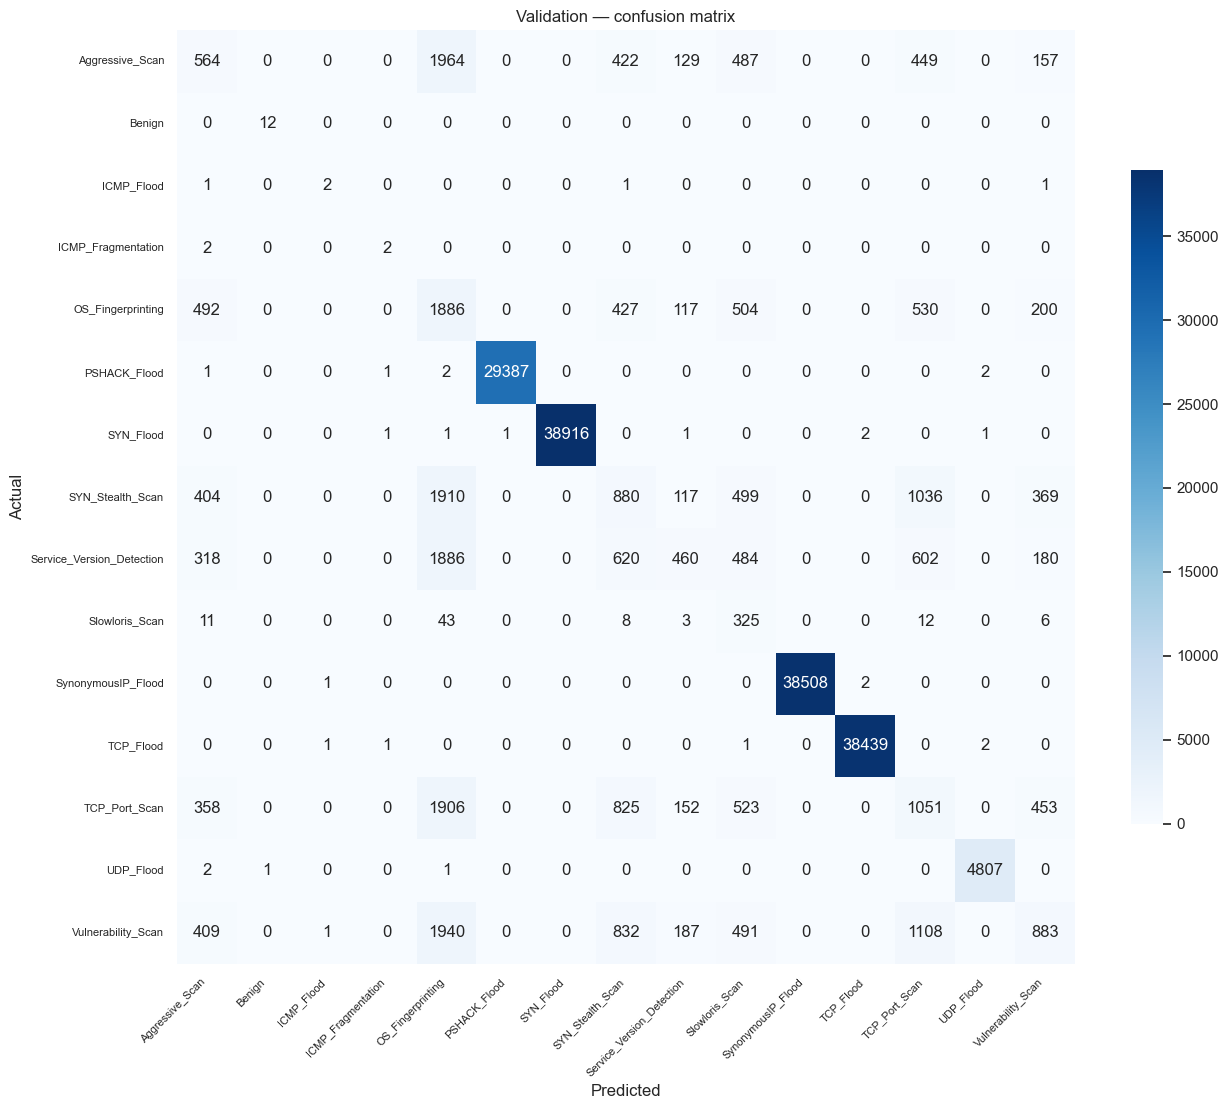

--- Test ---
Macro F1-Score : 0.5667   <- headline
Weighted F1    : 0.8679
Accuracy       : 0.8689   (inflated by the flood classes)

Classification report:


                           precision    recall  f1-score   support

          Aggressive_Scan       0.22      0.13      0.17      4172
                   Benign       1.00      0.92      0.96        12
               ICMP_Flood       0.45      1.00      0.62         5
       ICMP_Fragmentation       0.43      0.75      0.55         4
        OS_Fingerprinting       0.16      0.46      0.24      4155
             PSHACK_Flood       1.00      1.00      1.00     29393
                SYN_Flood       1.00      1.00      1.00     38922
         SYN_Stealth_Scan       0.22      0.17      0.19      5215
Service_Version_Detection       0.40      0.10      0.16      4551
           Slowloris_Scan       0.10      0.84      0.18       408
       SynonymousIP_Flood       1.00      1.00      1.00     38511
                TCP_Flood       1.00      1.00      1.00     38445
            TCP_Port_Scan       0.22      0.20      0.21      5269
                UDP_Flood       1.00      1.00      1.00     

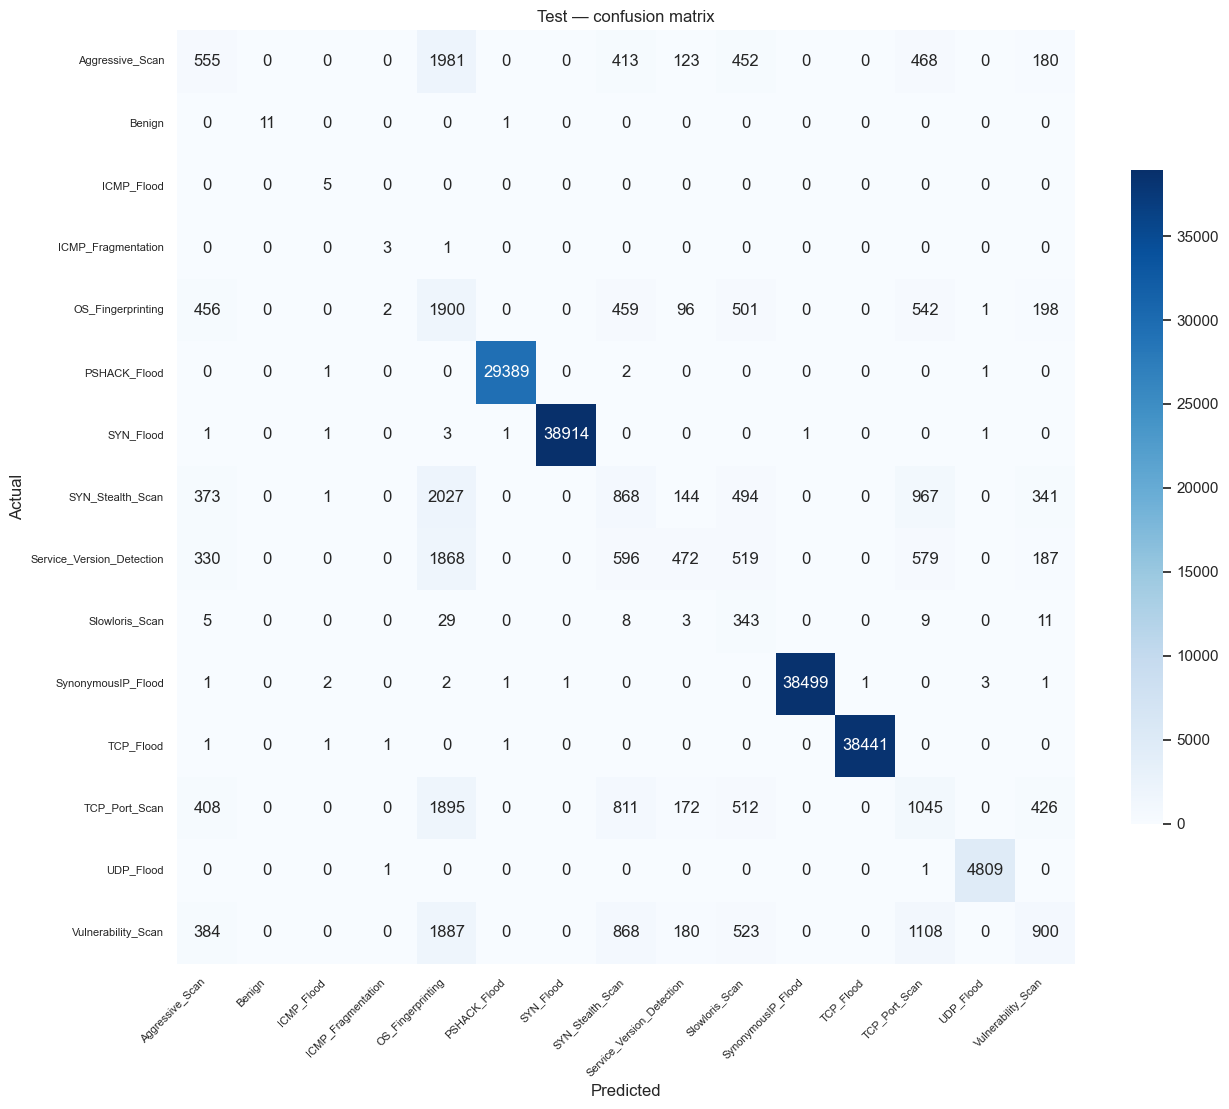

In [11]:
_ = evaluate_model(best_multi_model, X_val, y_val_multi, title_prefix="Validation")
_ = evaluate_model(best_multi_model, X_test, y_test_multi, title_prefix="Test")

## 5. Feature Importance Analysis

XGBoost reports how often each feature is used to split (gain-based for XGBoost, split count for LightGBM). Let's visualise the top 20 most important features.

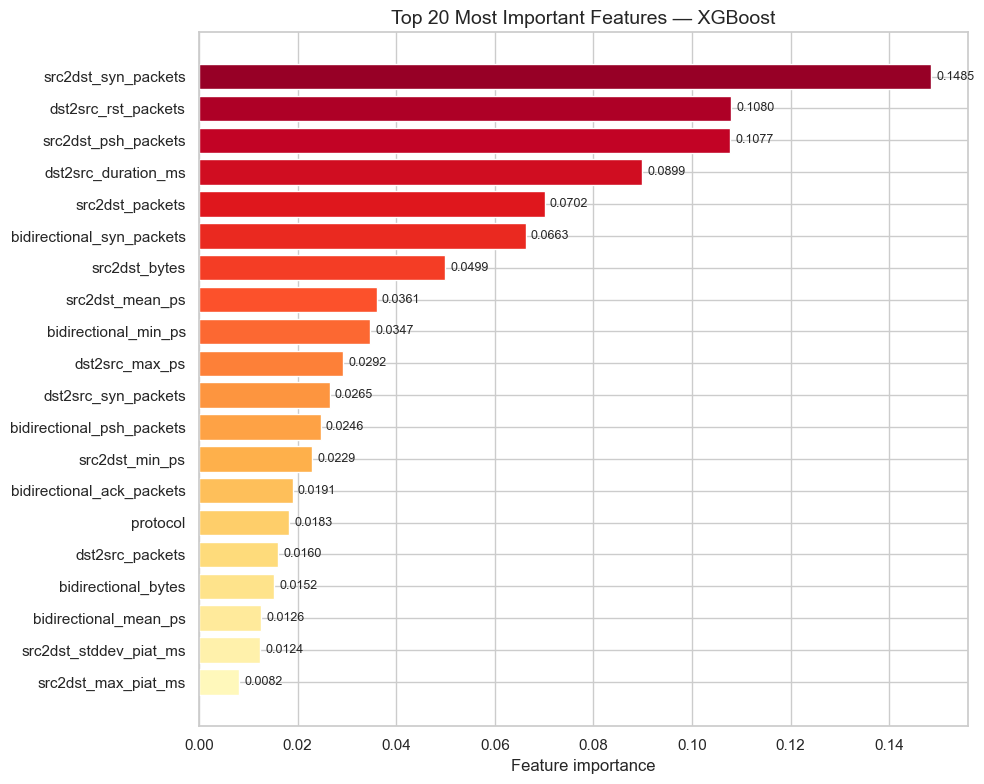


Top 20 Feature Importances:
                  Feature  Importance
      src2dst_syn_packets    0.148527
      dst2src_rst_packets    0.107987
      src2dst_psh_packets    0.107725
      dst2src_duration_ms    0.089935
          src2dst_packets    0.070151
bidirectional_syn_packets    0.066303
            src2dst_bytes    0.049944
          src2dst_mean_ps    0.036091
     bidirectional_min_ps    0.034703
           dst2src_max_ps    0.029225
      dst2src_syn_packets    0.026539
bidirectional_psh_packets    0.024642
           src2dst_min_ps    0.022935
bidirectional_ack_packets    0.019062
                 protocol    0.018267
          dst2src_packets    0.016042
      bidirectional_bytes    0.015227
    bidirectional_mean_ps    0.012591
   src2dst_stddev_piat_ms    0.012412
      src2dst_max_piat_ms    0.008180


In [12]:
importances = best_multi_model.feature_importances_

feature_names = X_train.columns



feat_imp_df = pd.DataFrame({

    'Feature': feature_names,

    'Importance': importances

}).sort_values('Importance', ascending=False)



top20 = feat_imp_df.head(20)



fig, ax = plt.subplots(figsize=(10, 8))

colors = sns.color_palette('YlOrRd_r', len(top20))

ax.barh(top20['Feature'][::-1], top20['Importance'][::-1], color=colors[::-1])

ax.set_xlabel('Feature importance', fontsize=12)

ax.set_title('Top 20 Most Important Features — XGBoost', fontsize=14)

for i, (val, name) in enumerate(zip(top20['Importance'][::-1], top20['Feature'][::-1])):

    ax.text(val + 0.001, i, f'{val:.4f}', va='center', fontsize=9)

plt.tight_layout()

plt.show()



print("\nTop 20 Feature Importances:")

print(top20.to_string(index=False))

## 6. Save Model

Export the multiclass model to the `saved_models` directory.

In [13]:
if os.path.exists('../../../saved_models'):

    SAVE_DIR = '../../../saved_models'

elif os.path.exists('saved_models'):

    SAVE_DIR = 'saved_models'

else:

    SAVE_DIR = '../saved_models'



os.makedirs(SAVE_DIR, exist_ok=True)

joblib.dump(best_multi_model, os.path.join(SAVE_DIR, "xgb_model_multiclass.pkl"))



print("Model saved successfully!")

Model saved successfully!


---

## Where the canonical numbers live

This notebook is for exploration. Every figure quoted in the write-up comes from
`src/evaluation/run_experiments.py`, which re-runs the split *and* model
initialisation across seeds 42 / 1337 / 2024 and reports mean ± standard
deviation. A single-seed result from this notebook will differ, and should not
be quoted on its own.

```bash
python3 src/evaluation/run_experiments.py --raw-dir data/raw --feature-set extended
```

| Reference | Location |
|---|---|
| Multi-seed results | `evaluation_results/multiseed/MULTISEED_RESULTS.md` |
| Full leakage audit | `docs/leakage_audit_results.md` |
| Feature-set diff vs. the reference implementation | `docs/dataset_feature_engineering.md` §3.4 |

**Headline for this dataset is macro-F1, not accuracy.** With `ICMP_Fragmentation`
at 28 flows and `Benign` at 82, accuracy tracks the volumetric floods and hides
the reconnaissance classes almost entirely — the corrected Random Forest scores
0.8679 accuracy against 0.5582 macro-F1 on the same predictions.